# Univariate Analysis of IMDb Dataset

## Objective

The objective of this notebook is to perform univariate analysis on the cleaned IMDb dataset to understand the distribution, characteristics, and patterns of individual variables using both statistical and visual analysis techniques.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Loading the Cleaned Dataset

The cleaned IMDb dataset was imported for exploratory data analysis and univariate analysis.


In [2]:
cleaned_data = pd.read_csv("clean_dataset_final.csv")

In [3]:
cleaned_data

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,"['thriller', 'drama', 'crime']",2026,4.5,94.0,TV-MA,NaN,1.3
1,28 Years Later: The Bone Temple,"['thriller', 'sci-fi']",2026,7.3,109.0,R,81.0,88.0
2,3 Body Problem,['fantasy'],2024,7.5,NaN,TV-MA,NaN,180.0
3,56 Days,['romance'],2026,6.7,NaN,TV-MA,NaN,9.6
4,A Big Bold Beautiful Journey,['romance'],2025,6.0,109.0,R,43.0,21.0
...,...,...,...,...,...,...,...,...
250,Young Sherlock,"['action', 'adventure']",2026,7.5,NaN,TV-14,NaN,26.0
251,Your Friends & Neighbors,"['drama', 'crime']",2025,7.7,NaN,TV-MA,NaN,53.0
252,Youth,['romance'],2026,7.1,140.0,Unknown,NaN,6.5
253,Zootopia,['animation'],2016,8.0,108.0,PG,78.0,635.0


In [4]:
import ast
dfu = cleaned_data.copy()
# Convert string representation of list to actual Python list
dfu["Genre"] = dfu["Genre"].apply(ast.literal_eval)
# Expand into separate rows
dfu = dfu.explode("Genre")
# Remove extra spaces (optional)
dfu["Genre"] = dfu["Genre"].str.strip()
# Reset index
dfu = dfu.reset_index(drop=True)

dfu.head()

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,thriller,2026,4.5,94.0,TV-MA,NaN,1.3
1,180,drama,2026,4.5,94.0,TV-MA,NaN,1.3
2,180,crime,2026,4.5,94.0,TV-MA,NaN,1.3
3,28 Years Later: The Bone Temple,thriller,2026,7.3,109.0,R,81.0,88.0
4,28 Years Later: The Bone Temple,sci-fi,2026,7.3,109.0,R,81.0,88.0


In [5]:
dfu

,Title,Genre,Year,Rating,Runtime,Certificate,Metascore,Votes_K
0,180,thriller,2026,4.5,94.0,TV-MA,NaN,1.3
1,180,drama,2026,4.5,94.0,TV-MA,NaN,1.3
2,180,crime,2026,4.5,94.0,TV-MA,NaN,1.3
3,28 Years Later: The Bone Temple,thriller,2026,7.3,109.0,R,81.0,88.0
4,28 Years Later: The Bone Temple,sci-fi,2026,7.3,109.0,R,81.0,88.0
...,...,...,...,...,...,...,...,...
490,Zootopia 2,comedy,2025,7.4,108.0,PG,73.0,128.0
491,Zootopia 2,animation,2025,7.4,108.0,PG,73.0,128.0
492,Zootopia 2,adventure,2025,7.4,108.0,PG,73.0,128.0
493,Zootopia 2,action,2025,7.4,108.0,PG,73.0,128.0


**Observations**
- Since many IMDb titles belong to multiple genres, the Genre column was split and expanded using the explode() function.
-  As a result, the dataset size increased from 255 unique titles to 495 title-genre records.
-  This transformation enabled independent genre-wise analysis while preserving the original title information.

In [6]:
# Categorical and Numerical data
# Categorical columns-Title, Genre,Year,Certificate
# Numerical columns- Rating,Runtime,Metascore,Votes_K

# Column Classification

The dataset variables were classified into categorical, numerical, and time-based variables to facilitate appropriate exploratory data analysis techniques.

**Categorical Variables**

- Title (Movie title/identifier)
- Genre
- Certificate

**Numerical Variables**

- Rating
- Runtime (minutes)
- Metascore
- Votes_K (vote count in thousands)

**Time-Based Variable**

- Year


# Univariate Analysis Structure

- Univariate analysis was performed to understand the characteristics and distribution of individual variables in the dataset. 
- Each variable was examined using both non-visual and visual techniques.

1. Non-Visual Analysis

Non-visual analysis focuses on numerical summaries and descriptive statistics.
The following techniques were used:

- Statistical summaries (mean, median, standard deviation, minimum, maximum, quartiles)
- Frequency analysis for categorical variables
- Missing value analysis
- Distribution measures such as skewness and kurtosis
- Outlier detection using the Interquartile Range (IQR) method
  
2. Visual Analysis

Visualizations were used to better understand distributions, patterns, and potential anomalies.
The following plots were used:

- Count plots for categorical variables
- Histograms for numerical variables
- Pie charts to visualize category proportions
- Boxplots for identifying spread and outliers

# Time Based Column 

## Year Column

### Year Column - Non Visual Analysis

In [7]:
dfu["Year"].describe()

count     495.000000
mean     2020.331313
std         8.512632
min      1972.000000
25%      2018.000000
50%      2025.000000
75%      2026.000000
max      2027.000000
Name: Year, dtype: float64

In [8]:
dfu["Year"].value_counts()

Year
2026    176
2025     85
2023     34
2019     19
2024     15
2021     15
2022     13
2011     12
2005     10
2013     10
2014      9
2016      9
2018      8
2020      7
2015      6
1999      6
2001      6
2008      6
2010      5
2027      5
2009      5
2006      4
1994      4
2003      4
2004      4
2007      3
1997      3
2017      2
2012      2
2000      2
1989      2
1988      1
1972      1
1987      1
2002      1
Name: count, dtype: int64

In [9]:
dfu["Year"].nunique()

35

In [10]:
dfu["Year"].unique()

array([2026, 2024, 2025, 1988, 2022, 2021, 2013, 2005, 2023, 2015, 2011,
       2014, 2008, 2020, 2006, 2009, 2019, 2010, 1994, 1999, 1997, 2001,
       2012, 2004, 2000, 2016, 2003, 2007, 1989, 2027, 2018, 1972, 2017,
       1987, 2002])

In [11]:
dfu["Year"].shape

(495,)

In [12]:
dfu["Year"].min()

1972

In [13]:
dfu["Year"].max()

2027

**Observations**

- The Year variable is a time-based variable with 35 unique release years.
- Release years range from 1972 to 2027, covering more than five decades of content.
- The dataset is heavily concentrated in recent years, with 2026 (176 titles) and 2025 (85 titles) being the most frequent.
- The mean release year is 2020.33 and the median is 2025, indicating that most titles are recent.
- Older titles are relatively underrepresented, while a few upcoming titles from 2027 are also included in the dataset.

### Year Column - Visual Analysis

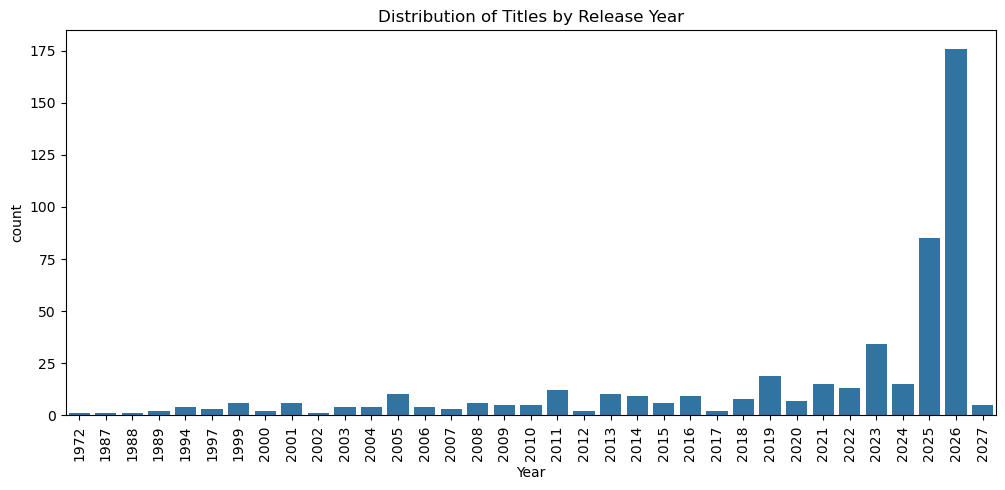

In [14]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(12,5))
sns.countplot(data=dfu, x="Year", order=sorted(dfu["Year"].unique()))
plt.xticks(rotation=90)
plt.title("Distribution of Titles by Release Year")
plt.show()

**Observations**
- The count plot shows that the dataset is dominated by recent titles, particularly from 2025 and 2026.
- The number of titles increases significantly in recent years, while older years have relatively few entries.
- This indicates that the IMDb search results used for scraping are heavily skewed toward contemporary and upcoming content

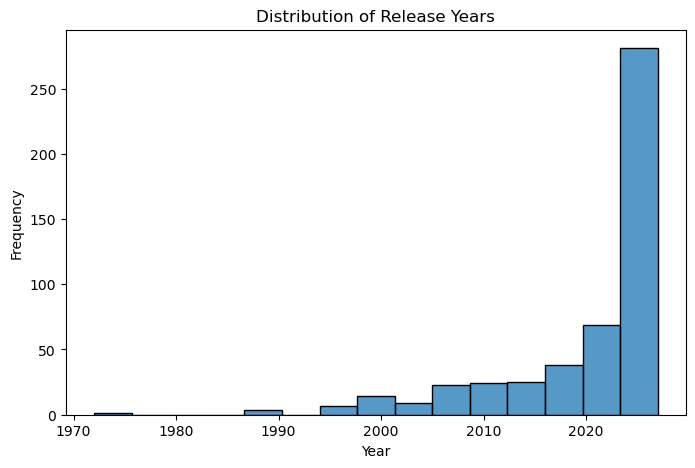

In [15]:
plt.figure(figsize=(8,5))
sns.histplot(dfu["Year"], bins=15)
plt.title("Distribution of Release Years")
plt.xlabel("Year")
plt.ylabel("Frequency")
plt.show()

**Observations**

- The histogram confirms that most titles are concentrated in the recent years, with frequencies increasing sharply after 2015.
- The distribution is left-skewed, as a small number of older titles extend the range back to 1972.

# Categorical Data

## Genre Column

### Genre Column - Non Visual Analysis
- Genre is a categorical variable representing the category/type of content.

In [16]:
dfu["Genre"].describe()

count          495
unique          10
top       thriller
freq            50
Name: Genre, dtype: object

In [17]:
dfu["Genre"].value_counts()

Genre
thriller     50
drama        50
crime        50
sci-fi       50
romance      50
animation    50
adventure    49
action       49
comedy       49
fantasy      48
Name: count, dtype: int64

In [18]:
dfu["Genre"].mode()

0    animation
1        crime
2        drama
3      romance
4       sci-fi
5     thriller
Name: Genre, dtype: object

In [19]:
dfu["Genre"].nunique()

10

In [20]:
dfu["Genre"].shape

(495,)

In [21]:
dfu["Genre"].isnull().sum()

np.int64(0)

**Observations:-** 
- After exploding the Genre column, the dataset contained 495 genre records distributed across 10 unique genres.
- The frequency distribution shows that the genres are fairly balanced, with most genres appearing approximately 48–50 times.
- Drama, Crime, Thriller, Sci-Fi, Romance, and Animation were the most frequent genres, each occurring 50 times, while Fantasy had the lowest frequency with 48 occurrences.
- The small variation in frequencies indicates that the dataset has relatively uniform genre representation, reducing the risk of heavy genre imbalance during analysis.
- Since the dataset was collected genre-wise from IMDb search pages, the near-equal frequency distribution across genres is expected.
- This balanced distribution is beneficial for comparative genre analysis such as rating trends, popularity analysis, and runtime comparisons across genres.

### Genre Column - Visual Analysis

C:\Users\Admin\AppData\Local\Temp\ipykernel_14656\166296324.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  g=sns.countplot(x="Genre",data=dfu,palette="Set1")


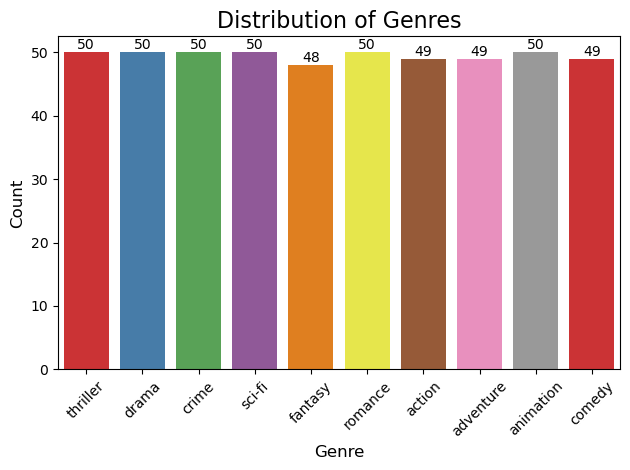

In [22]:
plt.title("Distribution of Genres",fontsize=16)
g=sns.countplot(x="Genre",data=dfu,palette="Set1")
plt.xlabel("Genre",fontsize=12)
plt.ylabel("Count",fontsize=12)
for i in g.containers:
    g.bar_label(i)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observations:-** 
- The countplot shows that genre frequencies are relatively balanced across the dataset, with most genres appearing nearly the same number of times.
- Drama, Crime, Thriller, Sci-Fi, Romance, and Animation were the most represented genres, while Fantasy had slightly fewer occurrences.
- The balanced distribution supports fair comparative analysis across genres.

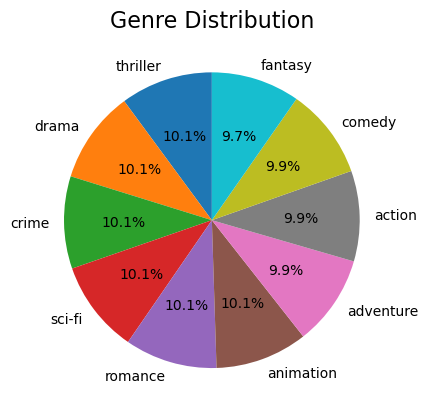

In [23]:
plt.title("Genre Distribution",fontsize=16)
plt.pie(
    dfu["Genre"].value_counts(),
    labels=dfu["Genre"].value_counts().index,
    autopct='%1.1f%%',
    startangle=90
)

plt.show()

**Observations:-**
- The pie chart illustrates that the genre distribution is relatively balanced across the dataset.
- Most genres contribute nearly equal proportions, with Drama, Crime, Thriller, Sci-Fi, Romance, and Animation slightly dominating the distribution.
-  Fantasy contributed the smallest proportion among all genres.
- The balanced distribution supports unbiased genre-wise comparisons during further analysis.

## Certificate Column

### Certificate Column - Non Visual Analysis

In [24]:
dfu["Certificate"].describe()

count       495
unique        9
top       TV-MA
freq        159
Name: Certificate, dtype: object

In [25]:
dfu["Certificate"].mode()

0    TV-MA
Name: Certificate, dtype: object

In [26]:
dfu["Certificate"].value_counts()

Certificate
TV-MA       159
R            87
TV-14        73
Unknown      63
PG-13        56
PG           33
TV-PG        18
TV-Y7-FV      4
G             2
Name: count, dtype: int64

In [27]:
dfu["Certificate"].shape

(495,)

In [28]:
dfu["Certificate"].nunique()

9

In [29]:
dfu["Certificate"].unique()

array(['TV-MA', 'R', 'PG-13', 'TV-14', 'PG', 'TV-Y7-FV', 'Unknown', 'G',
       'TV-PG'], dtype=object)

**Observations**
- The Certificate column contains 9 unique certification categories representing different audience suitability and parental guidance levels.
- The most frequently occurring certificate was TV-MA, appearing 159 times, indicating that mature audience content dominates the dataset.
- This was followed by R and TV-14, which also had relatively high frequencies.
- A considerable number of records were categorized as Unknown, suggesting that certification information was unavailable for some titles.
-  Family-oriented certifications such as G and TV-Y7-FV appeared very infrequently, indicating that the dataset primarily consists of content targeted toward teenage and adult audiences.

### Certificate column - Visual Analysis

C:\Users\Admin\AppData\Local\Temp\ipykernel_14656\84791097.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  c=sns.countplot(x="Certificate",data=dfu,palette="Set2")


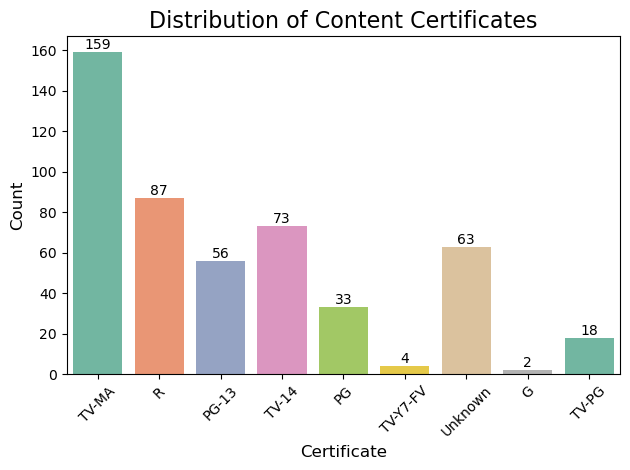

In [30]:
plt.title("Distribution of Content Certificates", fontsize=16)
c=sns.countplot(x="Certificate",data=dfu,palette="Set2")
plt.xlabel("Certificate", fontsize=12)
plt.ylabel("Count", fontsize=12)
for i in c.containers:
    c.bar_label(i)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

**Observations:-**
- The countplot shows that TV-MA is the most dominant certification category in the dataset, significantly exceeding all other certificate types.
- R and TV-14 also contribute a large portion of the records, reinforcing that the dataset mainly contains mature and teenage-oriented content.
- Certifications intended for children and general audiences, such as G and TV-Y7-FV, appear very rarely.
- Additionally, the presence of several Unknown entries indicates missing or unavailable certification information for some titles.

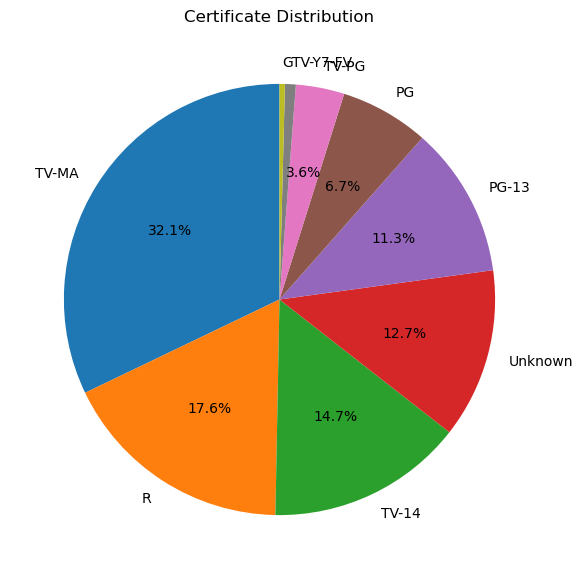

In [31]:
def func(pct):
    return ('%1.1f%%' % pct) if pct > 3 else ''

plt.figure(figsize=(10,7))

plt.pie(
    dfu["Certificate"].value_counts(),
    labels=dfu["Certificate"].value_counts().index,
    autopct=func,
    startangle=90
)

plt.title("Certificate Distribution")

plt.show()

**Observations:-**
- The pie chart shows that TV-MA constitutes the largest proportion of the dataset, contributing approximately one-third of all records.
- This indicates that mature audience content is highly dominant in the IMDb titles collected. -- R and TV-14 also represent significant portions of the dataset, further highlighting the strong presence of adult and teenage-oriented entertainment content.

- Certifications such as PG-13 and PG contribute moderate percentages, suggesting a smaller but noticeable presence of family and general-viewer content.
-  In contrast, categories like G and TV-Y7-FV occupy only a very small percentage of the dataset, indicating that children’s content is minimally represented.

- The Unknown category also accounts for a noticeable proportion of records, implying that certification information was unavailable or missing for several titles.
-  Overall, the percentage distribution confirms that the dataset is heavily skewed toward mature-content certifications.

# Numerical Data

## Statistical Measures 

The following statistical measures were used during numerical analysis:

* Mean → average value
* Median → central value
* Mode → most frequent value
* Variance → spread of data
* Standard Deviation → dispersion from mean
* Skewness → asymmetry of distribution
* Kurtosis → tail heaviness and outlier tendency


## Rating Column

### Rating Column - Non Visual Analysis

In [32]:
dfu["Rating"].describe()

count    440.000000
mean       7.590682
std        1.084654
min        4.500000
25%        6.900000
50%        7.800000
75%        8.400000
max        9.500000
Name: Rating, dtype: float64

In [33]:
dfu["Rating"].mean()

np.float64(7.590681818181817)

In [34]:
dfu["Rating"].median()

7.8

In [35]:
dfu["Rating"].skew()

np.float64(-0.8058703826440035)

In [36]:
dfu["Rating"].kurt()

np.float64(0.2791167554572067)

In [37]:
range=dfu["Rating"].max()-dfu["Rating"].min()
print(range)

5.0


In [38]:
dfu["Rating"].var()

1.1764733381652472

In [39]:
dfu["Rating"].std()

1.084653556747613

In [40]:
dfu["Rating"].isnull().sum()

np.int64(55)

**Observations:-**
- The Rating column contains 440 non-null observations, indicating that ratings were unavailable for a small number of titles, primarily upcoming releases.
- The average IMDb rating was approximately 7.59, while the median rating was 7.8, suggesting that most titles in the dataset received relatively high audience ratings.
- The ratings ranged from 4.5 to 9.5, resulting in a total range of 5.0.
-  The standard deviation of approximately 1.08 indicates moderate variability in ratings, meaning that most titles are clustered reasonably close to the average rating.
- The skewness value of approximately -0.81 indicates a moderately negatively skewed distribution.
- This suggests that the dataset contains a larger concentration of higher-rated titles, with fewer low-rated titles present.
- The kurtosis value of approximately 0.28 indicates that the distribution is close to a normal distribution with slightly heavier tails, implying the presence of a few ratings farther from the mean but without extreme concentration.

### Rating Column - Visual Analysis

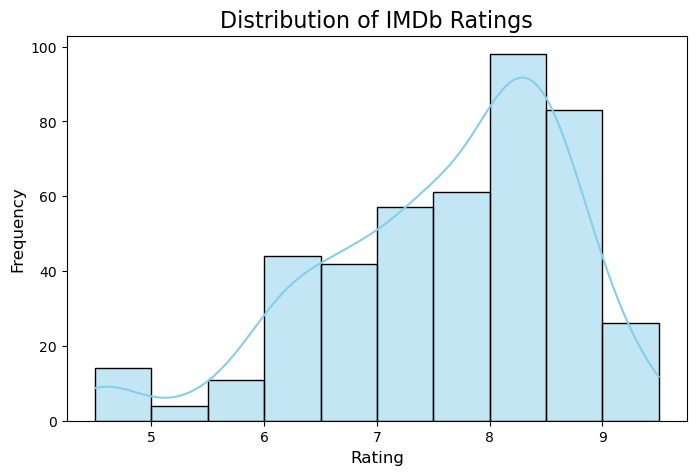

In [41]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=dfu,
    x="Rating",
    kde=True,
    bins=10,
    color="skyblue"
)

plt.title("Distribution of IMDb Ratings", fontsize=16)
plt.xlabel("Rating", fontsize=12)
plt.ylabel("Frequency", fontsize=12)

plt.show()

**Observations:-**
- The histogram shows that most IMDb ratings are concentrated between 7 and 9, indicating that the majority of titles in the dataset received relatively favorable audience ratings.
-  Very few titles have ratings below 6, suggesting that poorly rated content is less common in the dataset.
- The distribution appears moderately negatively skewed, with a longer tail toward lower ratings.
-  This observation aligns with the previously calculated negative skewness value.
-  The KDE curve further confirms that the ratings are clustered toward the higher end of the rating scale.
- The distribution does not appear perfectly symmetrical, but it remains relatively smooth without extreme irregularities, indicating a fairly consistent spread of ratings across titles.

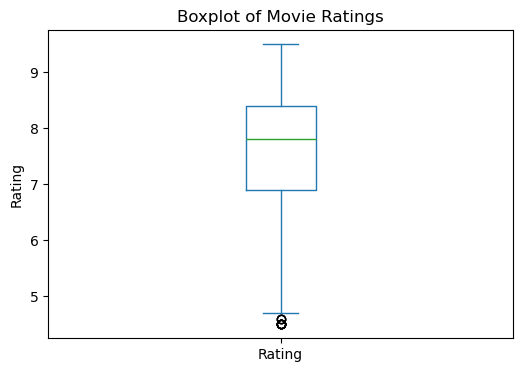

In [42]:
plt.figure(figsize=(6,4))
dfu["Rating"].plot(kind="box")
plt.title("Boxplot of Movie Ratings")
plt.ylabel("Rating")
plt.show()

**Observations:-**
- The boxplot indicates that the majority of IMDb ratings are concentrated within a relatively narrow range, with the median rating positioned toward the higher end of the scale.
- The distribution appears slightly negatively skewed, consistent with the previously calculated skewness value.
- A few lower-rated titles may be observed as potential outliers, although extreme outliers are not heavily prominent in the dataset.

## Runtime Column

### Runtime Column - Non Visual Analysis

In [43]:
dfu["Runtime"].head(20)

0      94.0
1      94.0
2      94.0
3     109.0
4     109.0
5       NaN
6       NaN
7     109.0
8       NaN
9       NaN
10      NaN
11      NaN
12    124.0
13     99.0
14     99.0
15     99.0
16      NaN
17     96.0
18      NaN
19      NaN
Name: Runtime, dtype: float64

In [44]:
dfu["Runtime"].describe()

count    212.000000
mean     124.235849
std       31.447105
min       81.000000
25%      104.000000
50%      114.000000
75%      140.000000
max      235.000000
Name: Runtime, dtype: float64

In [45]:
dfu["Runtime"].mean()

np.float64(124.23584905660377)

In [46]:
dfu["Runtime"].median()

114.0

In [47]:
dfu["Runtime"].mode()

0    99.0
Name: Runtime, dtype: float64

In [48]:
dfu["Runtime"].var()

988.9204149154978

In [49]:
dfu["Runtime"].std()

31.447105032347537

In [50]:
dfu["Runtime"].skew()

np.float64(1.4286885360943813)

In [51]:
dfu["Runtime"].kurt()

np.float64(2.0000166928450716)

In [52]:
dfu["Runtime"].isnull().sum()

np.int64(283)

**Observations:-**

- The Runtime column contains 212 non-null observations, while 283 entries are missing.
-  The missing runtime values were retained as null values because imputing random runtimes could introduce misleading information into the dataset.
-  Most missing values correspond to unreleased or upcoming titles where runtime information was not yet available.
- The average runtime of titles in the dataset is approximately 124 minutes, while the median runtime is 114 minutes.
- Since the mean is greater than the median, the distribution appears positively skewed, indicating the presence of some titles with significantly longer runtimes.
- The most frequently occurring runtime was 99 minutes, suggesting that many titles are concentrated around standard feature-length durations.
- Runtime values ranged from 81 minutes to 235 minutes, producing a moderately wide spread in movie durations.
- The standard deviation of approximately 31.45 minutes and variance of approximately 988.92 indicate moderate variability in runtimes across the dataset.
- The skewness value of approximately 1.43 confirms a positively skewed distribution, meaning a small number of titles have unusually high runtimes compared to the majority of titles.
-  Additionally, the kurtosis value of approximately 2.00 suggests a distribution with heavier tails and a sharper peak than a normal distribution, indicating the presence of potential runtime outliers.



### Runtime Column - Visual Analysis


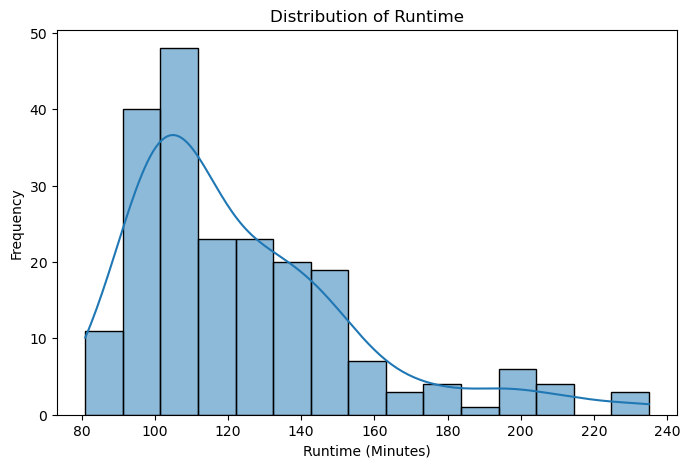

In [53]:
plt.figure(figsize=(8,5))
r=sns.histplot(
    data=dfu,
    x="Runtime",
    kde=True,
    bins=15
)
for container in r.containers:
    r.bar_label(container)
plt.title("Distribution of Runtime")
plt.xlabel("Runtime (Minutes)")
plt.ylabel("Frequency")
plt.show()

**Observations**
- The histogram shows that most titles have runtimes concentrated between approximately 90 and 140 minutes, indicating that the majority of content in the dataset follows standard feature-length durations.
-  The KDE curve further confirms that the distribution is not symmetrical and is skewed toward higher runtime values.
- A smaller number of titles have significantly longer runtimes extending beyond 180 minutes, which contributes to the positive skewness observed in the numerical analysis.
- The distribution gradually tapers toward the higher runtime range, indicating that extremely long-duration titles are relatively uncommon.
- The histogram also demonstrates moderate variability in runtimes, with a noticeable concentration around the 100–120 minute range, consistent with the calculated mode and median values.

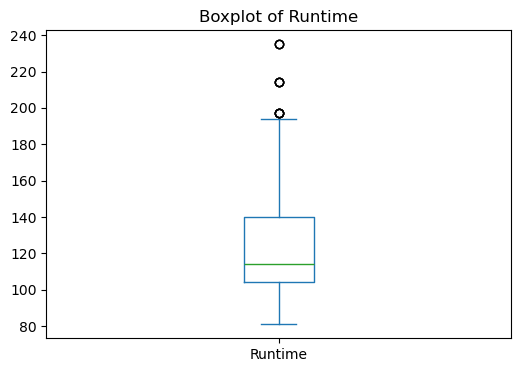

In [54]:
plt.figure(figsize=(6,4))
dfu["Runtime"].plot(kind="box")
plt.title("Boxplot of Runtime")
plt.show()

**Observations**
- The boxplot indicates that the central portion of runtime values is concentrated within a moderate range, with the median runtime positioned slightly below the center of the box.
- The upper whisker extends farther than the lower whisker, visually confirming the positively skewed nature of the runtime distribution.
- Several higher runtime values appear beyond the upper whisker, suggesting the presence of potential outliers corresponding to unusually long-duration titles.
- These outliers are consistent with the previously calculated positive skewness and higher kurtosis values.
- Overall, the boxplot confirms that while most titles have moderately similar runtimes, a few exceptionally long titles increase the spread of the distribution.

## Metascore Column

### Metascore Column - Non Visual Analysis

In [55]:
dfu["Metascore"].describe()

count    166.000000
mean      63.120482
std       15.914847
min       33.000000
25%       53.000000
50%       64.000000
75%       73.000000
max      100.000000
Name: Metascore, dtype: float64

In [56]:
dfu["Metascore"].mean()

np.float64(63.12048192771084)

In [57]:
dfu["Metascore"].median()

64.0

In [58]:
dfu["Metascore"].mode()

0    73.0
Name: Metascore, dtype: float64

In [59]:
dfu["Metascore"].skew()

np.float64(-0.05194038174417483)

In [60]:
dfu["Metascore"].kurt()

np.float64(-0.5346295565238983)

In [61]:
dfu["Metascore"].var()

253.28236582694424

In [62]:
dfu["Metascore"].std()

15.914847339102698

In [63]:
dfu["Metascore"].isnull().sum()

np.int64(329)

**Observations**
- The Metascore column contains 166 non-null observations, while 329 values are missing.
- The large number of missing values suggests that Metascore ratings were unavailable for many titles, which is common for unreleased content, television shows, or titles without sufficient critic reviews.
- Since imputing arbitrary values could distort the analysis, the missing values were retained as null entries.
- The average Metascore of the dataset is approximately 63.12, while the median score is 64, indicating that critic ratings are generally centered around the mid-to-high score range.
- The close proximity between the mean and median suggests that the distribution is relatively symmetrical.
- The most frequently occurring Metascore was 73, indicating that several titles received favorable critic reviews around this score range.
- Metascore values ranged from 33 to 100, showing a broad spread of critic evaluations across titles.
- The standard deviation of approximately 15.91 and variance of approximately 253.28 indicate moderate variability in critic scores.
- This suggests that while many titles cluster around the average score, some titles received substantially higher or lower critic ratings.
- The skewness value of approximately 0.05 is very close to zero, indicating that the distribution is nearly symmetrical with no strong left or right skew.
- Additionally, the kurtosis value of approximately -0.53 suggests a slightly flatter distribution compared to a normal distribution, meaning the scores are more evenly spread without extreme concentration around the mean.

### Metascore Column - Visual Analysis

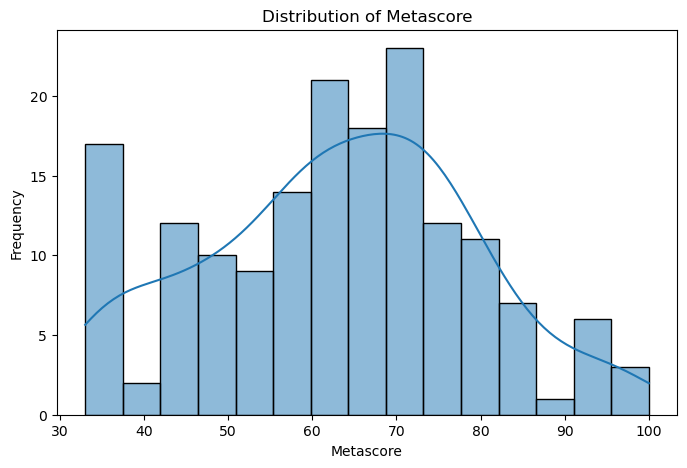

In [64]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=dfu,
    x="Metascore",
    kde=True,
    bins=15
)

plt.title("Distribution of Metascore")
plt.xlabel("Metascore")
plt.ylabel("Frequency")

plt.show()

**Observations**
- The histogram shows that most Metascore values are concentrated between approximately 50 and 75, indicating that the majority of titles received moderate to favorable critic reviews.
- The KDE curve appears relatively smooth and symmetrical, supporting the earlier numerical finding that the distribution is close to normal.
- Unlike the runtime distribution, the Metascore distribution does not show strong skewness toward either lower or higher values.
- This suggests that critic ratings are more evenly distributed across the dataset.
- Extremely low and extremely high Metascore values occur less frequently, while mid-range scores dominate the dataset.
- The overall spread indicates moderate variability in critic reviews without excessive concentration around a single score range.

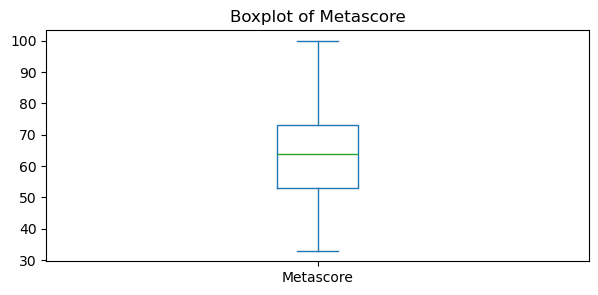

In [65]:
plt.figure(figsize=(7,3))

dfu["Metascore"].plot(kind="box")

plt.title("Boxplot of Metascore")

plt.show()

**Observations**
- The boxplot indicates that the central portion of Metascore values is distributed within a moderate range, with the median positioned near the center of the box.
- This visually confirms the near-symmetrical nature of the distribution observed in the skewness analysis.
- The whiskers on both sides appear relatively balanced, suggesting that the distribution does not contain strong left or right skewness.
- A few values near the extremes may appear as mild outliers, but no severe outlier concentration is visible.
- Overall, the boxplot confirms that critic scores are fairly evenly distributed across titles, with moderate spread and limited extreme deviations from the average Metascore.

## Votes_K Column

### Votes_K Column - Non Visual Analysis

In [66]:
dfu["Votes_K"].describe()

count     440.000000
mean      306.723605
std       510.937997
min         0.562000
25%        27.000000
50%       128.000000
75%       331.000000
max      2800.000000
Name: Votes_K, dtype: float64

In [67]:
dfu["Votes_K"].mean()

np.float64(306.7236045454545)

In [68]:
dfu["Votes_K"].median()

128.0

In [69]:
dfu["Votes_K"].mode()

0     16.0
1    205.0
Name: Votes_K, dtype: float64

In [70]:
dfu["Votes_K"].var()

261057.6368053972

In [71]:
dfu["Votes_K"].std()

510.9379970264466

In [72]:
dfu["Votes_K"].skew()

np.float64(3.1372819934307605)

In [73]:
dfu["Votes_K"].kurt()

np.float64(10.594382208054723)

In [74]:
dfu["Votes_K"].isnull().sum()

np.int64(55)

**Observations:-**
- The Votes_K column contains 440 non-null observations, while 55 values are missing.
- The vote counts were standardized into thousands (K) to maintain consistency and simplify analysis.
- Missing values were retained as null entries because vote information was unavailable for certain titles, particularly upcoming or recently announced releases.
- The average number of votes is approximately 306.72K, whereas the median is 128K. Since the mean is substantially higher than the median, the distribution is highly positively skewed. This indicates that while most titles received moderate vote counts, a smaller number of extremely popular titles accumulated exceptionally large numbers of votes.
- Vote counts range from approximately 0.56K to 2800K votes, showing a very wide variation in audience engagement across the dataset. The large standard deviation of approximately 510.94K and variance of approximately 261057.64 further confirm the presence of substantial variability in title popularity.
- The dataset is bimodal, with the most frequently occurring vote counts being 16K and 205K votes. This suggests that multiple clusters of popularity exist within the dataset.
- The skewness value of approximately 3.14 indicates a strongly right-skewed distribution, meaning that a few highly popular titles heavily influence the overall average vote count.
- Additionally, the kurtosis value of approximately 10.59 indicates a highly leptokurtic distribution with heavy tails and extreme outliers.
- This suggests the presence of several titles with exceptionally high vote counts compared to the majority of the dataset.

### Votes_K Column - Visual Analysis

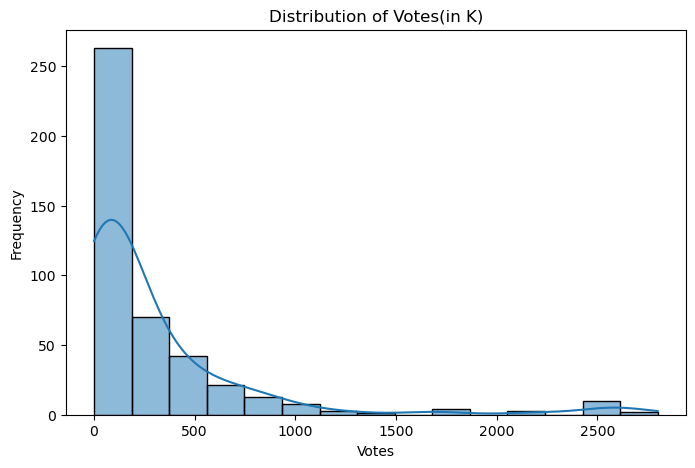

In [75]:
plt.figure(figsize=(8,5))

sns.histplot(
    data=dfu,
    x="Votes_K",
    kde=True,
    bins=15
)

plt.title("Distribution of Votes(in K)")
plt.xlabel("Votes")
plt.ylabel("Frequency")

plt.show()

**Observations**
- The histogram shows that the majority of titles received relatively lower to moderate numbers of IMDb votes, with a large concentration of titles clustered toward the lower end of the vote scale.
- As the vote count increases, the frequency of titles decreases significantly.
- The distribution is strongly positively skewed, with a long right tail extending toward extremely high vote counts. This indicates that only a small number of titles achieved exceptionally high popularity levels compared to the rest of the dataset.
- The KDE curve further confirms the uneven distribution of audience engagement, showing a dense concentration of titles with comparatively lower vote counts and a gradual tapering toward the higher end.
- The presence of a few blockbuster or highly popular titles heavily influences the overall shape of the distribution.

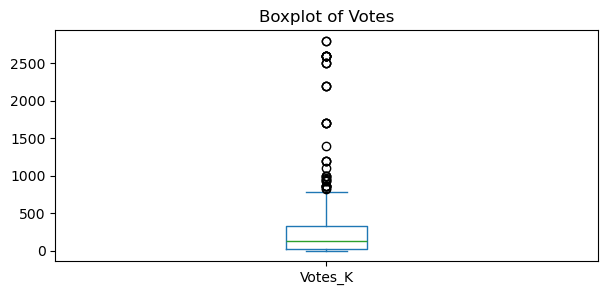

In [76]:
plt.figure(figsize=(7,3))

dfu["Votes_K"].plot(kind="box")

plt.title("Boxplot of Votes")

plt.show()

**Observations**
- The boxplot clearly indicates the presence of numerous high-value outliers in the Votes_K column.
- Most titles are concentrated within the lower portion of the vote range, while several titles extend far beyond the upper whisker due to exceptionally large vote counts.
- The median vote count is positioned closer to the lower quartile, visually confirming the strong positive skewness observed in the numerical analysis.
- The upper whisker is considerably longer than the lower whisker, indicating that the distribution is heavily stretched toward higher vote values.
- Overall, the boxplot confirms that the dataset contains a few extremely popular titles with very large audience engagement, while the majority of titles maintain comparatively moderate popularity levels.

# Conclusion of Univariate Analysis

The univariate analysis revealed several important patterns within the IMDb dataset:

* Genre distribution remained relatively balanced after exploding multi-genre entries.
* Mature-content certifications dominated the dataset.
* IMDb ratings were concentrated toward higher values.
* Runtime and vote distributions were positively skewed.
* Metascore displayed a relatively balanced distribution.
* Vote counts contained extreme popularity outliers.
* The dataset was heavily concentrated toward recent and upcoming release years.

Overall, the analysis provided a strong understanding of the individual characteristics and distributions of the dataset variables.
